# Feature analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from EDA_and_modeling.functional_files import _data

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

Data File: Libraries loaded!


## Data

In [2]:
df_orig, _ = _data.get_data('1')

## Feature acknowledgement

In [3]:
df = df_orig.copy()

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   amount_usd                    699960 non-null  float64
 1   hours_since_last_txn          699960 non-null  float64
 2   txn_count_last_24h            699960 non-null  int64  
 3   distance_from_home_km         699960 non-null  float64
 4   card_age_months               699960 non-null  int64  
 5   customer_age                  699960 non-null  int64  
 6   account_balance_usd           699960 non-null  float64
 7   cvv_retry_count               699960 non-null  int64  
 8   velocity_score                699960 non-null  float64
 9   time_of_day_hour              699960 non-null  int64  
 10  day_of_week                   699960 non-null  int64  
 11  merchant_risk_score           699960 non-null  float64
 12  prior_disputes                699960 non-null  int64  


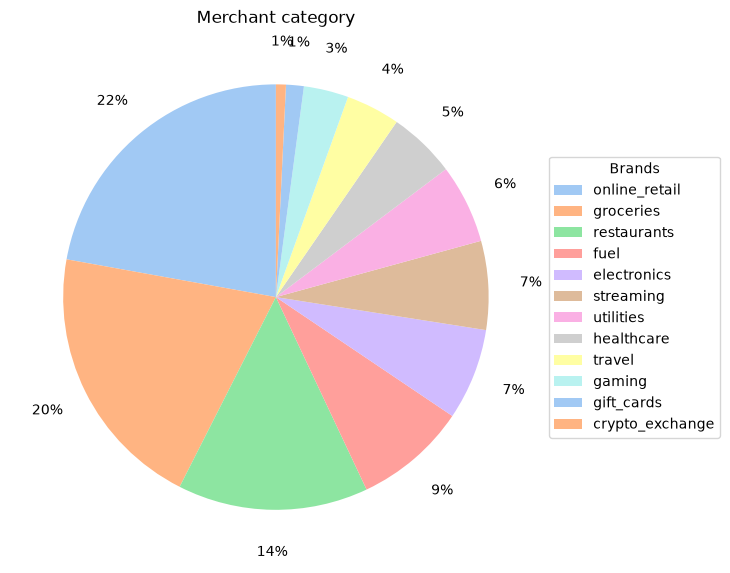

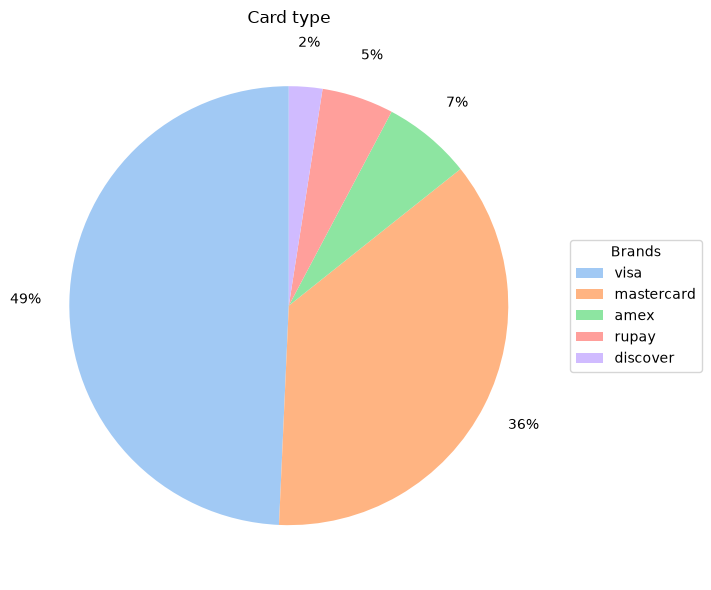

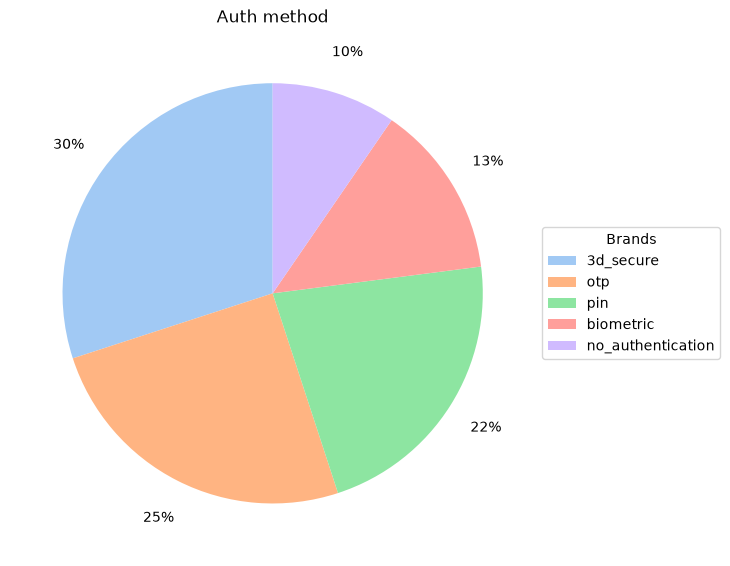

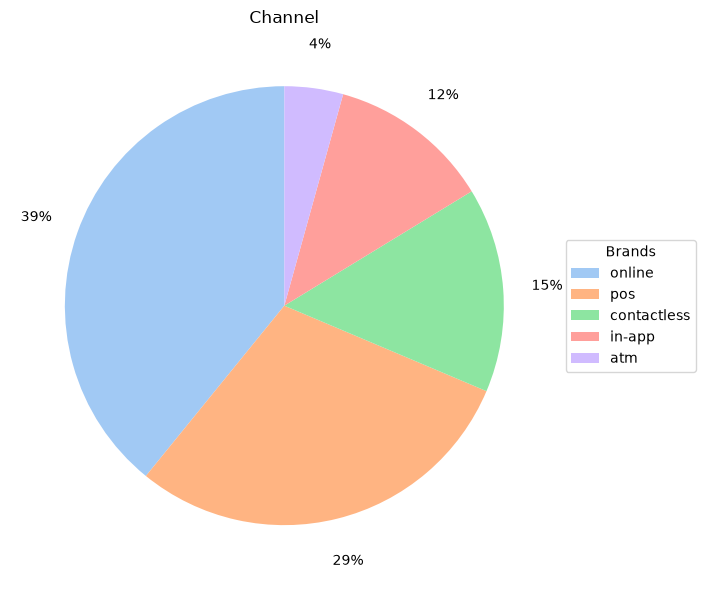

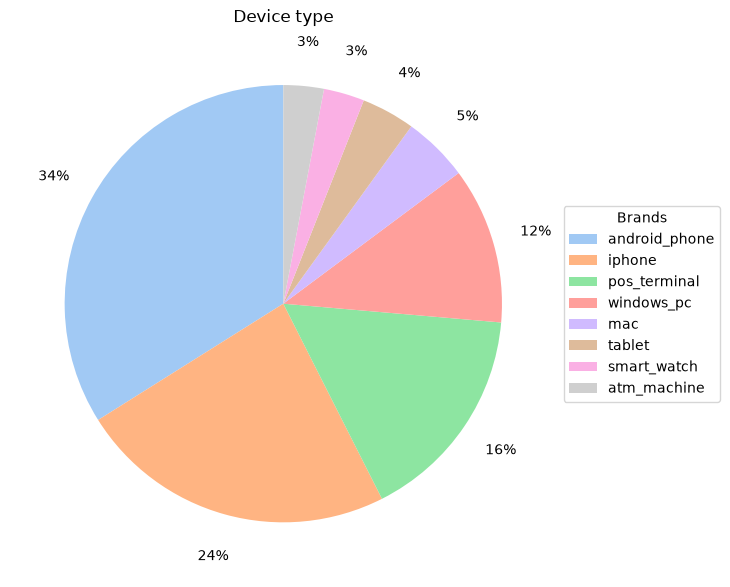

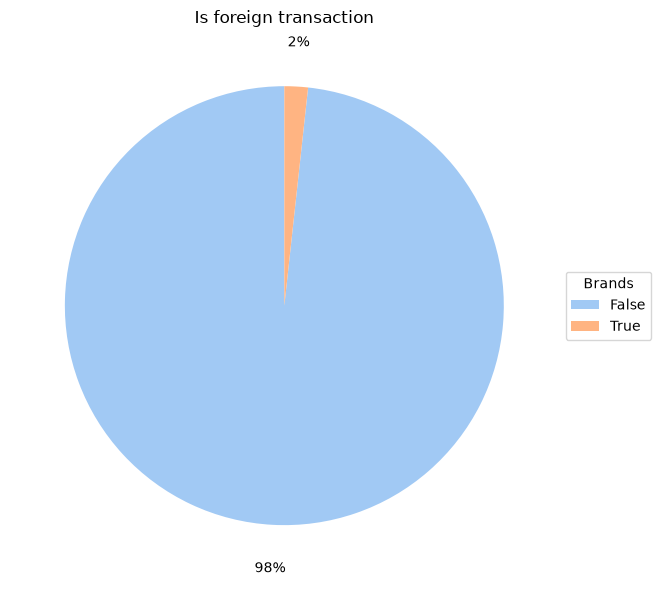

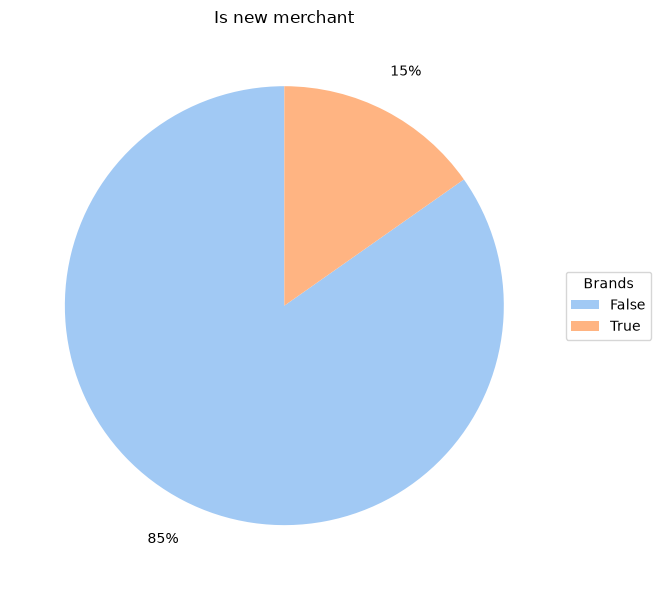

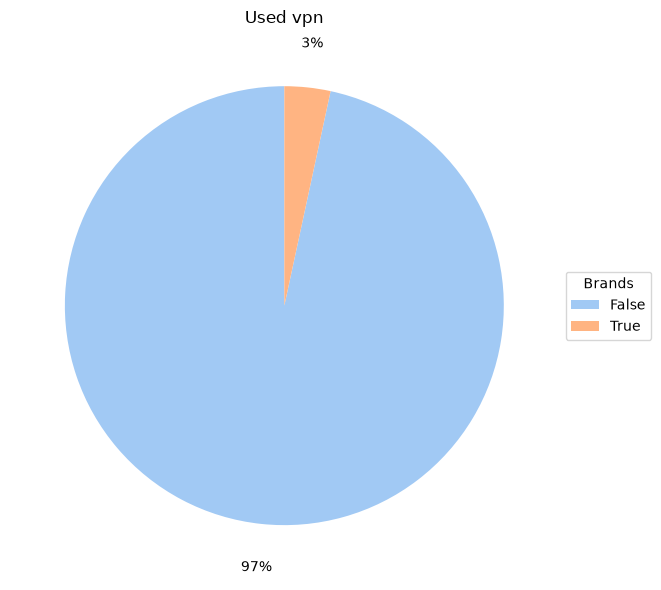

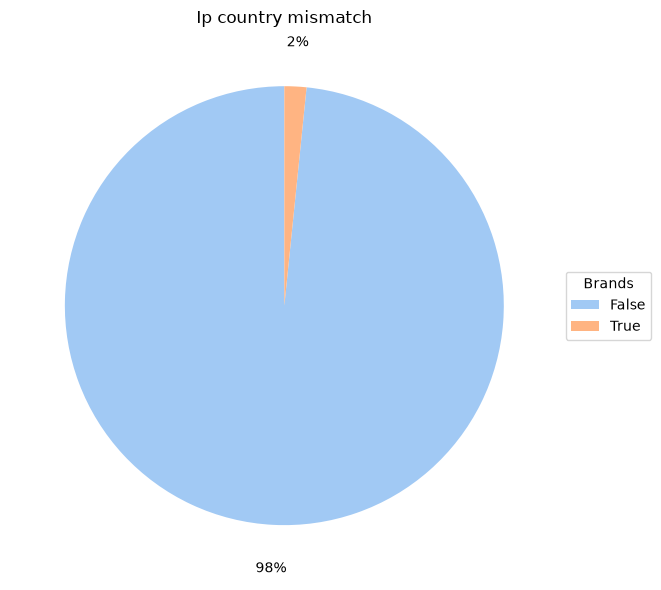

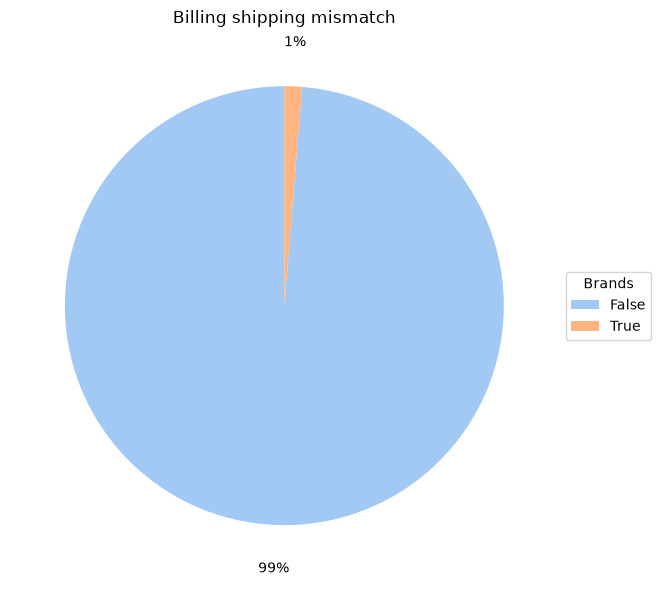

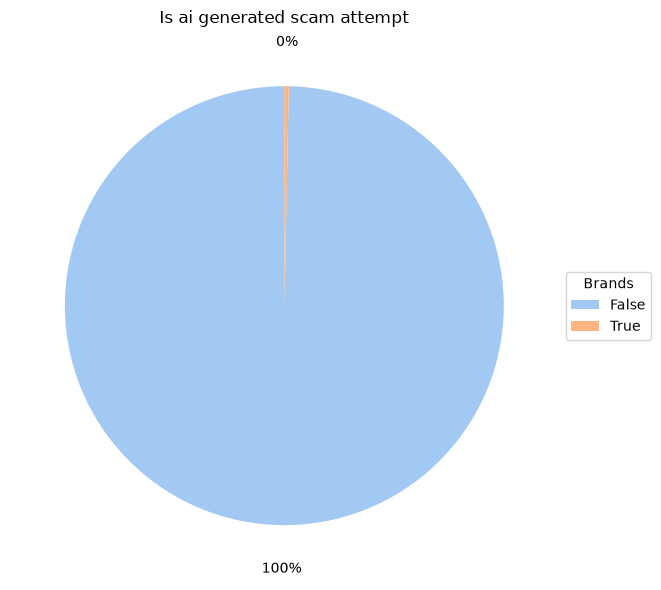

In [5]:
for col in df.dtypes[(df.dtypes == 'str') | (df.dtypes == 'bool')].index:
    mode = df[col].astype('str').value_counts()
    labels = list(mode.index)
    colors = sns.color_palette('pastel')[0:len(labels)]
    plt.figure(figsize=(7, 6))
    wedges, texts, autotexts = plt.pie(
        mode,
        colors=colors,
        autopct='%.0f%%',
        startangle=90,
        pctdistance=1.2  # Pushes percentage numbers closer to the outer edge
    )
    plt.legend(wedges, labels, title="Brands", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
    plt.title(str(col).replace('_', ' ').capitalize())
    plt.tight_layout()
    plt.show()

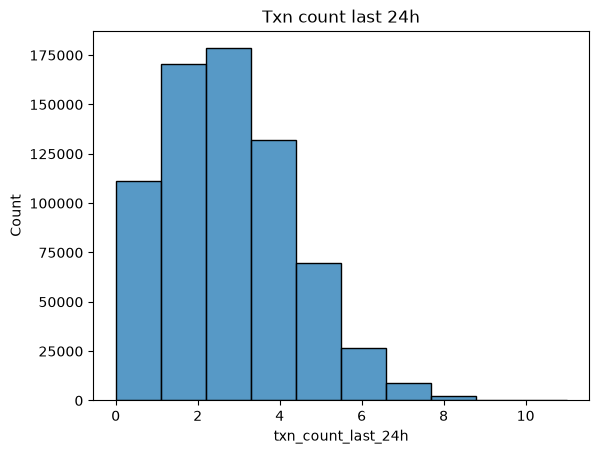

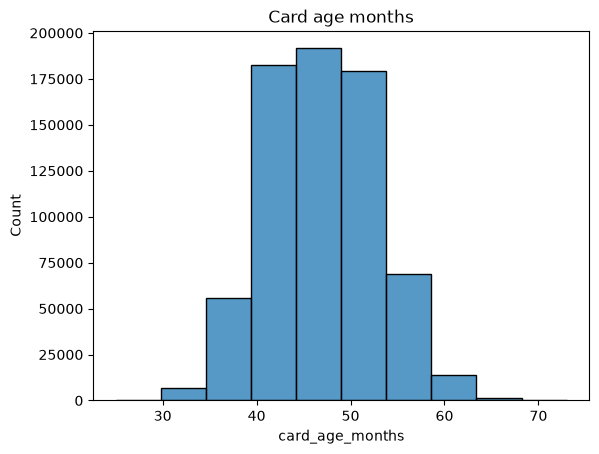

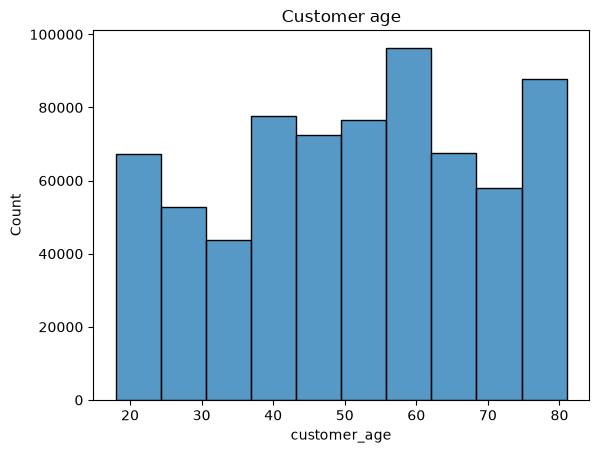

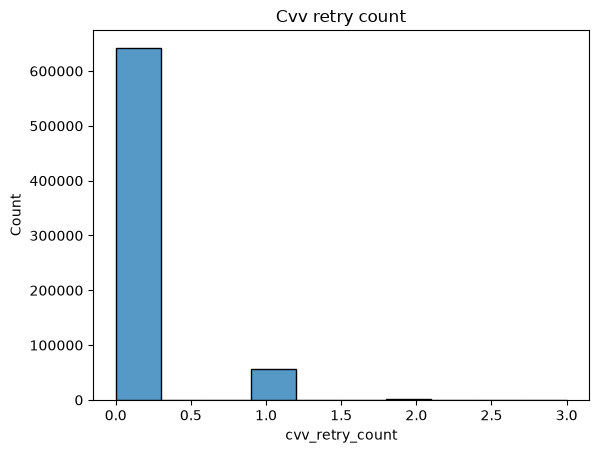

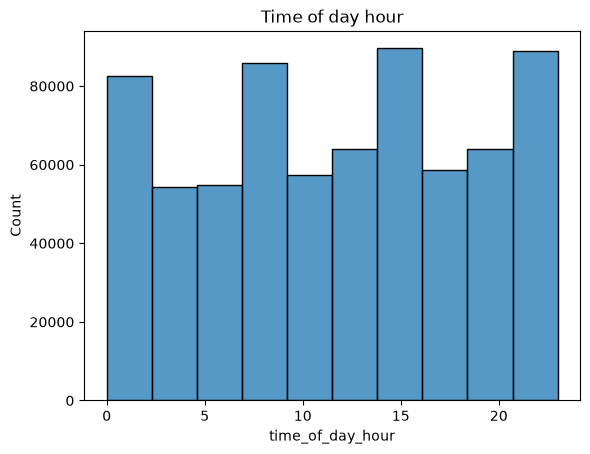

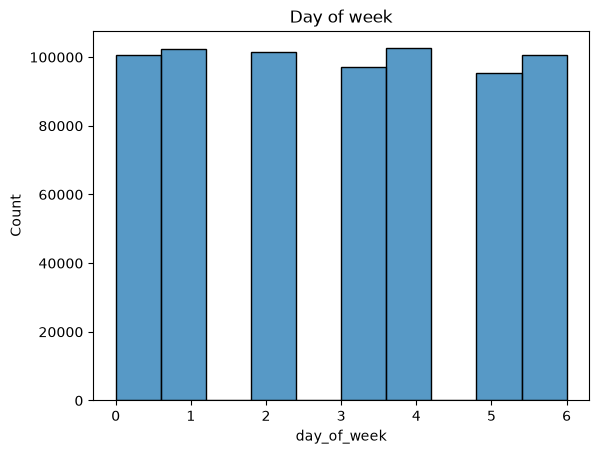

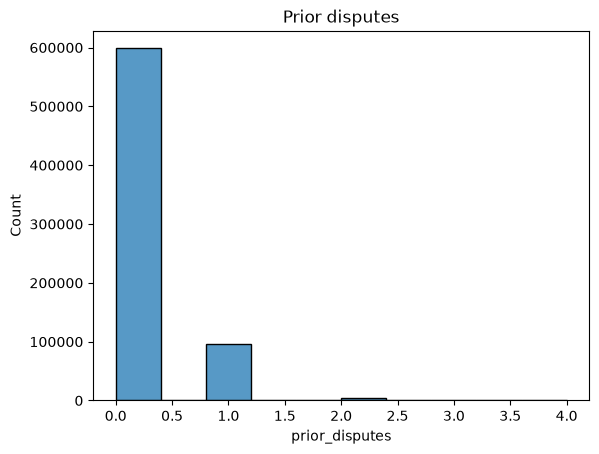

In [6]:
for col in df.dtypes[(df.dtypes == 'int') | (df.dtypes == 'flaot')].index:
    sns.histplot(x=col, data=df, bins=10)
    plt.title(str(col).replace('_', ' ').capitalize())
    plt.show()

#### Conclusion 2
Model has several categorical features as well as numberical.